In [ ]:
### ABOUT THIS NOTEBOOK!

# this notebook is used to analyze and visualization of several points in Moran's I autocorrelation analysis
# 1. Global Moran's I
# 2. Local Moran's I
# 3. Autocorrelation Interpretation

# REQUIREMENT!
# please install those library first before running the code.

# pip install numpy
# pip install geopandas
# pip install pandas
# pip install matplotlib
# pip install esda'
# pip install libpysal
# pip install splot

# 01 Import the following library.
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from esda.moran import Moran, Moran_Local
from libpysal.weights import Queen, Rook, KNN
from splot.esda import moran_scatterplot, lisa_cluster
import warnings
warnings.filterwarnings("ignore")

In [25]:
# 02 Import main data (data, included 24 variables)
data = gpd.read_file("../data/main_data.gpkg")

In [27]:
# 03 Spatial weight 
print(f"Total data cell : {len(data)}")
print(f"Label 1 (suitable): {data['label'].sum()} ({data['label'].mean()*100:.1f}%)")
print(f"Label 0 (not suitable): {(data['label']==0).sum()} ({(1-data['label'].mean())*100:.1f}%)")

w_queen = Queen.from_dataframe(data, silence_warnings=True)
w_queen.transform = "r"

w_rook = Rook.from_dataframe(data, silence_warnings=True)
w_rook.transform = "r"

print(f"\nSpatial Weights (Queen Contiguity):")
print(f"Mean neighbors per cell : {w_queen.mean_neighbors:.2f}")
print(f"Min neighbors           : {w_queen.min_neighbors}")
print(f"Max neighbors           : {w_queen.max_neighbors}")
print(f"Islands (no neighbors)  : {len(w_queen.islands)}")


Total data cell : 16785
Label 1 (suitable): 352 (2.1%)
Label 0 (not suitable): 16433 (97.9%)

Spatial Weights (Queen Contiguity):
Mean neighbors per cell : 5.40
Min neighbors           : 0
Max neighbors           : 6
Islands (no neighbors)  : 4


In [28]:
# 04 Global Moran's I
y = data["label"].values.astype(float)

moran_queen = Moran(y, w_queen, permutations=999)
moran_rook  = Moran(y, w_rook,  permutations=999)

print("GLOBAL MORAN'S I RESULTS")

def print_moran_results(moran_obj, weight_type):
    print(f"\n[{weight_type} Contiguity]")
    print(f"Moran's I       : {moran_obj.I:.4f}")
    print(f"Expected I (H0) : {moran_obj.EI:.4f}")
    print(f"Variance        : {moran_obj.VI_sim:.6f}")
    print(f"Z-score         : {moran_obj.z_sim:.4f}")
    print(f"P-value (sim)   : {moran_obj.p_sim:.4f}")
    print(f"P-value (norm)  : {moran_obj.p_norm:.4f}")

    sig = moran_obj.p_sim < 0.05
    if sig and moran_obj.I > moran_obj.EI:
        interp = "Clustered (positif)"
    elif sig and moran_obj.I < moran_obj.EI:
        interp = "Dispersed (negatif)"
    else:
        interp = "Random — tidak ada pola spasial signifikan"
    print(f"Significance    : {'Yes (p<0.05)' if sig else 'Tidak'}")
    print(f"Interpretation  : {interp}")

print_moran_results(moran_queen, "Queen")
print_moran_results(moran_rook,  "Rook")

GLOBAL MORAN'S I RESULTS

[Queen Contiguity]
Moran's I       : 0.1142
Expected I (H0) : -0.0001
Variance        : 0.000024
Z-score         : 23.5009
P-value (sim)   : 0.0010
P-value (norm)  : 0.0000
Significance    : Yes (p<0.05)
Interpretation  : Clustered (positif)

[Rook Contiguity]
Moran's I       : 0.1142
Expected I (H0) : -0.0001
Variance        : 0.000023
Z-score         : 24.0567
P-value (sim)   : 0.0010
P-value (norm)  : 0.0000
Significance    : Yes (p<0.05)
Interpretation  : Clustered (positif)


In [30]:
# 05 Local Moran's I (LISA)
lisa = Moran_Local(y, w_queen, permutations=999, seed=42)

quadrant_map = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
data["lisa_q"]     = lisa.q
data["lisa_Is"]    = lisa.Is
data["lisa_p_sim"] = lisa.p_sim
data["lisa_quad"]  = data["lisa_q"].map(quadrant_map)
data["lisa_sig"]   = data["lisa_p_sim"] < 0.05

def lisa_label(row):
    if not row["lisa_sig"]:
        return "Not Significant"
    return row["lisa_quad"]

data["lisa_cluster"] = data.apply(lisa_label, axis=1)

lisa_counts = data["lisa_cluster"].value_counts()
print("LOCAL MORAN'S I (LISA) RESULTS")
print(f"\nLISA cluster distribution (p<0.05):")
for cat in ["HH", "HL", "LH", "LL", "Not Significant"]:
    n = lisa_counts.get(cat, 0)
    print(f"{cat:<20}: {n:>5} cell ({n/len(data)*100:.1f}%)")

print(f"\nKeterangan:")
print(f"HH = High-High  : hotspot")
print(f"LL = Low-Low    : coldspot")
print(f"HL = High-Low   : outlier")
print(f"LH = Low-High   : outlier")

LOCAL MORAN'S I (LISA) RESULTS

LISA cluster distribution (p<0.05):
HH                  :   117 cell (0.7%)
HL                  :   180 cell (1.1%)
LH                  :   779 cell (4.6%)
LL                  : 10629 cell (63.3%)
Not Significant     :  5080 cell (30.3%)

Keterangan:
HH = High-High  : hotspot
LL = Low-Low    : coldspot
HL = High-Low   : outlier
LH = Low-High   : outlier


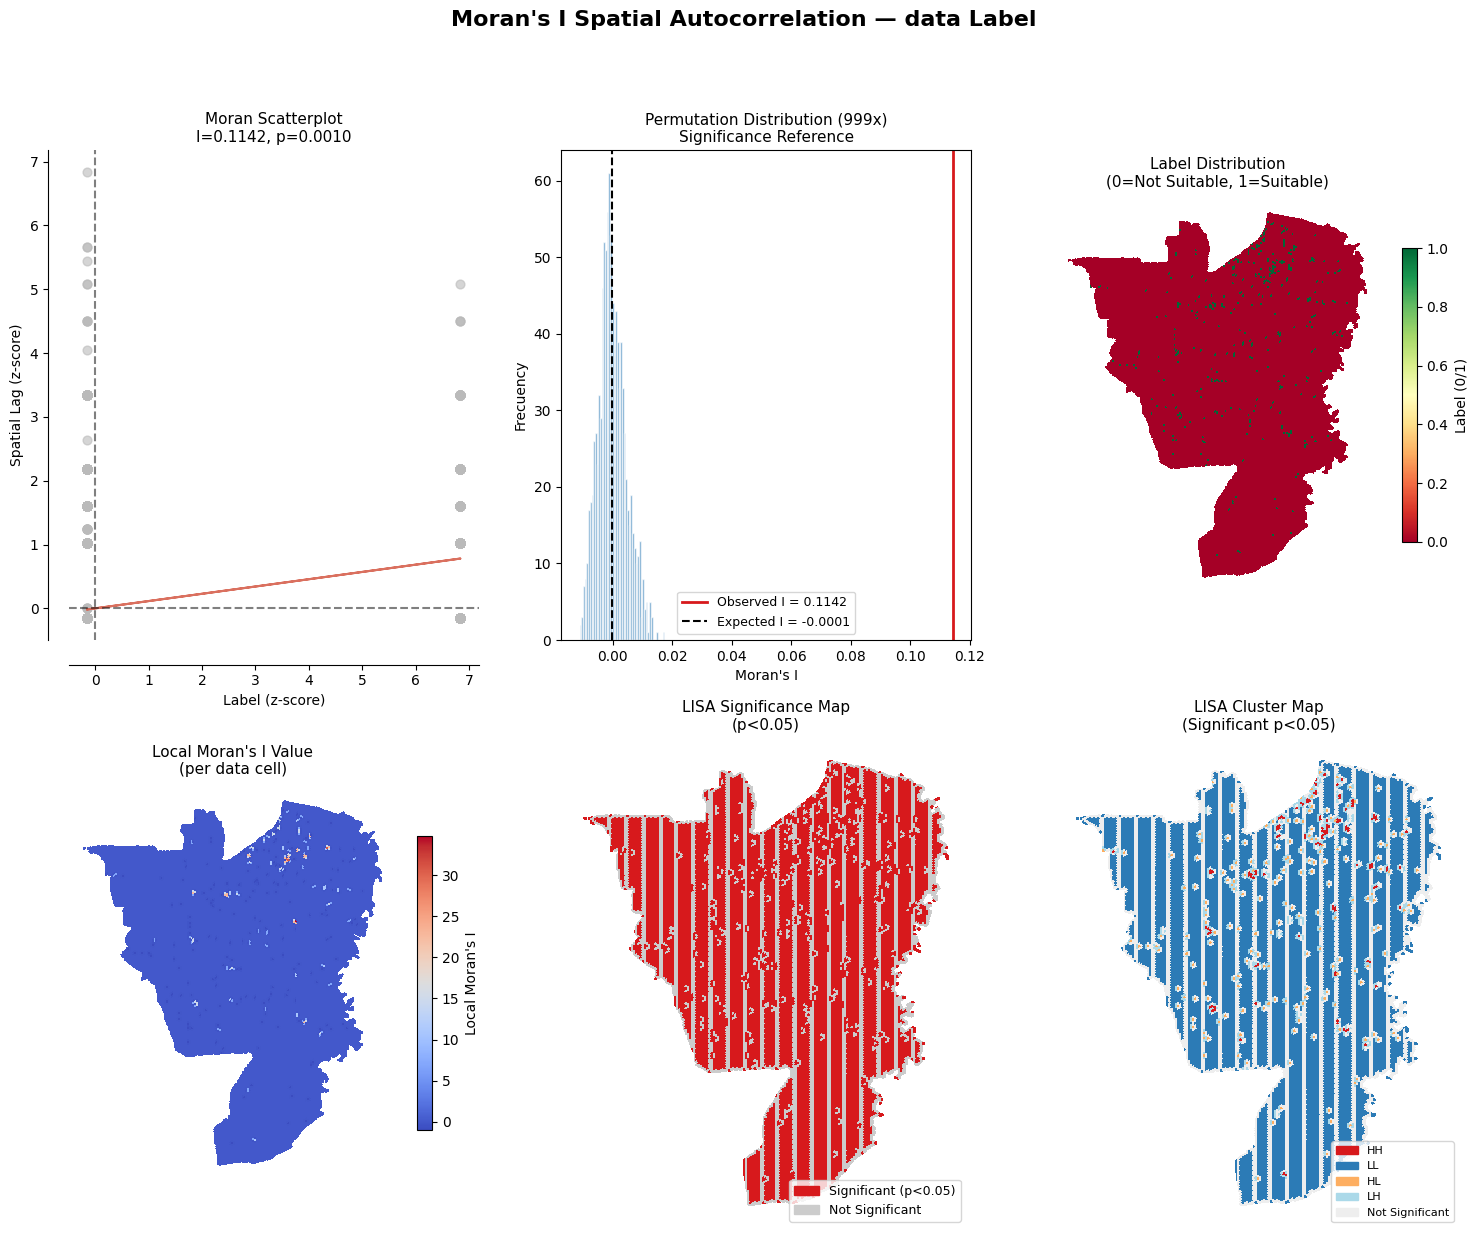

In [ ]:
# 06 Visualization of Global moran's I and local moran's I (LISA).
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Moran's I Spatial Autocorrelation — data Label", fontsize=16, fontweight="bold", y=0.98)

ax1 = fig.add_subplot(2, 3, 1)
moran_scatterplot(moran_queen, ax=ax1, aspect_equal=False)
ax1.set_title(f"Moran Scatterplot\nI={moran_queen.I:.4f}, p={moran_queen.p_sim:.4f}", fontsize=11)
ax1.set_xlabel("Label (z-score)", fontsize=10)
ax1.set_ylabel("Spatial Lag (z-score)", fontsize=10)

ax2 = fig.add_subplot(2, 3, 2)
ax2.hist(moran_queen.sim, bins=50, color="#2c7bb6", alpha=0.7, edgecolor="white")
ax2.axvline(moran_queen.I, color="#d7191c", linewidth=2, label=f"Observed I = {moran_queen.I:.4f}")
ax2.axvline(moran_queen.EI, color="black", linewidth=1.5, linestyle="--", label=f"Expected I = {moran_queen.EI:.4f}")
ax2.set_title("Permutation Distribution (999x)\nSignificance Reference", fontsize=11)
ax2.set_xlabel("Moran's I", fontsize=10)
ax2.set_ylabel("Frecuency", fontsize=10)
ax2.legend(fontsize=9)

ax3 = fig.add_subplot(2, 3, 3)
data.plot(column="label", ax=ax3, cmap="RdYlGn", legend=True,
    legend_kwds={"label": "Label (0/1)", "shrink": 0.6}, edgecolor="none", linewidth=0, antialiased=False)
ax3.set_title("Label Distribution\n(0=Not Suitable, 1=Suitable)", fontsize=11)
ax3.set_axis_off()

ax4 = fig.add_subplot(2, 3, 4)
data.plot(column="lisa_Is", ax=ax4, cmap="coolwarm", legend=True,
    legend_kwds={"label": "Local Moran's I", "shrink": 0.6},edgecolor="none", linewidth=0, antialiased=False)
ax4.set_title("Local Moran's I Value\n(per data cell)", fontsize=11)
ax4.set_axis_off()

ax5 = fig.add_subplot(2, 3, 5)
sig_colors = data["lisa_sig"].map({True: "#d7191c", False: "#cccccc"})
data.plot(color=sig_colors, ax=ax5, edgecolor="none", linewidth=0, antialiased=False)
patch_sig   = mpatches.Patch(color="#d7191c", label="Significant (p<0.05)")
patch_nsig  = mpatches.Patch(color="#cccccc", label="Not Significant")
ax5.legend(handles=[patch_sig, patch_nsig], fontsize=9, loc="lower right")
ax5.set_title("LISA Significance Map\n(p<0.05)", fontsize=11)
ax5.set_axis_off()

ax6 = fig.add_subplot(2, 3, 6)
lisa_color_map = {
    "HH":              "#d7191c",  
    "LL":              "#2c7bb6",  
    "HL":              "#fdae61",  
    "LH":              "#abd9e9",  
    "Not Significant": "#eeeeee", 
}
data["_color"] = data["lisa_cluster"].map(lisa_color_map)
data.plot(color=data["_color"], ax=ax6, edgecolor="none", linewidth=0, antialiased=False)
patches = [mpatches.Patch(color=v, label=k) for k, v in lisa_color_map.items()]
ax6.legend(handles=patches, fontsize=8, loc="lower right")
ax6.set_title("LISA Cluster Map\n(Significant p<0.05)", fontsize=11)
ax6.set_axis_off()